In [144]:
import matplotlib.pyplot as plt
import numpy as np
import math
import graphviz

In [145]:
def f(x):
    return (x**2+3.14)/x

def g(x):
    return x**2

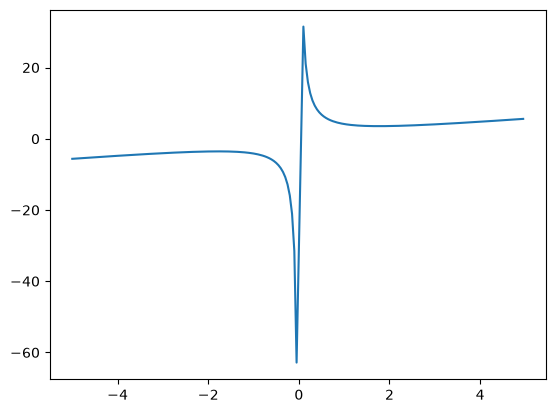

In [13]:
xs = np.arange(-5,5,.05)

bad_point = np.where((xs > -.05) & (xs < .05))
xs = np.delete(xs, bad_point)

ys = f(xs)
plt.plot(xs, ys)

0.6511227403560582


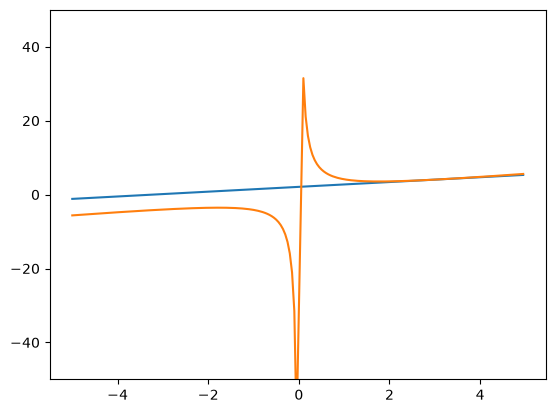

In [146]:
# find derivative line, and approximation
h = 0.0001
x = 3
f(x)
f(x+h)

# definition of slope at that point
slope = (f(x+h)-f(x))/h

# then we get b as a result by manipulating f(point) = point*slope + b
b = -(x * slope) + f(x)
def df_tan_line(xs, slope, b):
    return xs*slope + b

dys = df_tan_line(xs, slope, b)

# visual proof that this is the derivative
plt.plot(xs, dys)
plt.plot(xs, ys)
plt.ylim(-50, 50)
print(slope)


In [149]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        print_text = f"Value data=({self.data})"
        return print_text

    def __add__(self, b: Value):
        out = Value(self.data + b.data, (self, b), '+')
        return out

    def __mul__(self, b: Value):
        out = Value(self.data * b.data, (self, b), '*')
        return out

In [150]:
# recursively build out the graph to show all relations
def trace(root):
    nodes, edges = set(), set()
    # start at a node and build this tiny portion of the graph
    def build(node):
        # if the node isn't already in the graph, then add it, and then add its children
        if node not in nodes:    
            nodes.add(node)
            for child in node._prev:
                edges.add((child, node))
                # For each of its children repeat this process and they will 'go off on their own to build theirs'
                build(child)
    build(root)
    return nodes, edges



In [151]:
def make_computation_graph(loss_function_node):

    # Make the graph object
    dot = graphviz.Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    # Get all nodes and edges so we can prepare to actually make the graph viz
    nodes, edges = trace(loss_function_node)

    # Build all the nodes in space, and also build a special op node that already has an edge
    for node in nodes:
        uid = str(id(node))
        # build the node
        dot.node(name = uid, label = f'{{ {node.label} | {node.data:.4f} | grad {node.grad:.4f}}}', shape='record')
        if node._op:
            _op_name = uid + node._op
            # build the op node, and connect it to the parent immediately
            dot.node(name = _op_name, label=node._op)
            dot.edge(_op_name, uid)
    # for the rest of the edges, connect them to the floating nodes now
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot
    

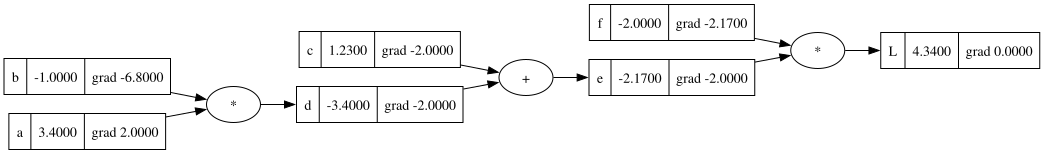

In [143]:
a = Value(3.4, label='a')
b = Value(-1.0, label='b')
c = Value(1.23, label='c') 
d = a*b; d.label='d'
e = d+c; e.label = 'e'
f = Value(-2.0, label='f')
L = e*f; L.label = 'L'

# We show how we got these down below
f.grad = -2.17# dL/df
e.grad = -2.0
d.grad = -2.0
c.grad = -2.0
a.grad = 2.0
b.grad = -6.8

make_computation_graph(L)

# By Hand
First we'll do the gradients by hand, complete them, and then verify the output using the approximate verification below

$$\frac{\partial L}{\partial L} = 1$$

$$\frac{\partial L}{\partial e} = \frac{\partial (e \cdot f)}{\partial e} = f = -2.0$$

$$\frac{\partial L}{\partial f} = \frac{\partial (e \cdot f)}{\partial f} = e = -2.17$$

## Chain Rule
Now we start getting into chain rule since we need to extend our rate of change beyond just the local derivative w.r.t $L$. Instead, we need to go further down into $d$ and $c$. We can think of this as gear ratios. If we move the $d$ gear by $h$ rotations, then $e$ will rotate accordingly, which then rotates $L$. The grad tells us by how much this rotation matters as it propagates to $L$.

$$\frac{\partial L}{\partial d} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial d} = -2.0 \cdot 1 = -2.0$$

$$\frac{\partial L}{\partial c} = \frac{\partial L}{\partial e} \cdot \frac{\partial e}{\partial c} = -2.0 \cdot 1 = -2.0$$

$$\frac{\partial L}{\partial a} = \frac{\partial L}{\partial d} \cdot \frac{\partial d}{\partial a} = -2.0 \cdot -1.0 = 2.0$$

$$\frac{\partial L}{\partial b} = \frac{\partial L}{\partial d} \cdot \frac{\partial d}{\partial b} = -2.0 \cdot 3.4 = -6.8$$


In [140]:
f.grad = -2.17# dL/df
e.grad = -2.0
d.grad = -2.0
c.grad = -2.0
a.grad = 2.0
b.grad = -6.8


In [142]:
def verify_gradient():

    h = 0.0001

    a = 3.4
    b = -1.0
    c = 1.23
    d = a*b
    e = d+c
    f = -2.0
    L1 = e*f
    print(L1)

    a = 3.4
    a += h
    
    b = -1.0
    # b += h
    
    c = 1.23
    # c += h

    d = a*b
    # d += h

    e = d+c
    # e += h

    f = -2.0
    # f += h

    L2 = e*f
    print(L2, L1, (L2 - L1), round((L2-L1)/h, 11))

verify_gradient()

4.34
4.3402 4.34 0.00020000000000042206 2.0
